<a href="https://colab.research.google.com/github/Aryanshh/CSET343/blob/main/Lab5_1758.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Download Dermatology dataset from UCI

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/dermatology/dermatology.data"

columns = [
    "erythema",
    "scaling",
    "definite_borders",
    "itching",
    "koebner_phenomenon",
    "polygonal_papules",
    "follicular_papules",
    "oral_mucosal_involvement",
    "knee_and_elbow_involvement",
    "scalp_involvement",
    "family_history",
    "melanin_incontinence",
    "eosinophils_infiltrate",
    "PNL_infiltrate",
    "fibrosis_of_the_papillary_dermis",
    "exocytosis",
    "acanthosis",
    "hyperkeratosis",
    "parakeratosis",
    "clubbing_of_the_rete_ridges",
    "elongation_of_the_rete_ridges",
    "thinning_of_the_suprapapillary_epidermis",
    "spongiform_pustule",
    "munro_microabcess",
    "focal_hypergranulosis",
    "disappearance_of_the_granular_layer",
    "vacuolisation_and_damage_of_basal_layer",
    "spongiosis",
    "saw_tooth_appearance_of_retes",
    "follicular_horn_plug",
    "perifollicular_parakeratosis",
    "inflammatory_monoluclear_infiltrate",
    "band_like_infiltrate",
    "age",
    "class"
]

df = pd.read_csv(
    url,
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset downloaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset downloaded successfully!
Shape: (366, 35)


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw_tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_infiltrate,band_like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3


In [3]:
# Display basic information about the dataset

print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape:
(366, 35)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   erythema                                  366 non-null    int64  
 1   scaling                                   366 non-null    int64  
 2   definite_borders                          366 non-null    int64  
 3   itching                                   366 non-null    int64  
 4   koebner_phenomenon                        366 non-null    int64  
 5   polygonal_papules                         366 non-null    int64  
 6   follicular_papules                        366 non-null    int64  
 7   oral_mucosal_involvement                  366 non-null    int64  
 8   knee_and_elbow_involvement                366 non-null    int64  
 9   scalp_involvement                         366 non-null    int6

In [4]:
# Display first 10 rows

df.head(10)

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw_tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_infiltrate,band_like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3
5,2,3,2,0,0,0,0,0,0,0,...,0,0,2,0,0,0,1,0,41.0,2
6,2,1,0,2,0,0,0,0,0,0,...,0,0,0,0,0,0,2,0,18.0,5
7,2,2,3,3,3,3,0,2,0,0,...,2,2,3,2,0,0,3,3,57.0,3
8,2,2,1,0,2,0,0,0,0,0,...,0,0,2,0,0,0,2,0,22.0,4
9,2,2,1,0,1,0,0,0,0,0,...,0,0,2,0,0,0,2,0,30.0,4


In [5]:
# Summary statistics for all numerical features

summary_statistics = df.describe().T

summary_statistics["median"] = df.median(numeric_only=True)

summary_statistics = summary_statistics[
    ["count", "mean", "median", "std", "min", "25%", "50%", "75%", "max"]
]

summary_statistics

,count,mean,median,std,min,25%,50%,75%,max
erythema,366.0,2.068306,2.0,0.664753,0.0,2.0,2.0,2.00,3.0
scaling,366.0,1.795082,2.0,0.701527,0.0,1.0,2.0,2.00,3.0
definite_borders,366.0,1.549180,2.0,0.907525,0.0,1.0,2.0,2.00,3.0
itching,366.0,1.366120,1.0,1.138299,0.0,0.0,1.0,2.00,3.0
koebner_phenomenon,366.0,0.633880,0.0,0.908016,0.0,0.0,0.0,1.00,3.0
polygonal_papules,366.0,0.448087,0.0,0.957327,0.0,0.0,0.0,0.00,3.0
follicular_papules,366.0,0.166667,0.0,0.570588,0.0,0.0,0.0,0.00,3.0
oral_mucosal_involvement,366.0,0.377049,0.0,0.834147,0.0,0.0,0.0,0.00,3.0
knee_and_elbow_involvement,366.0,0.614754,0.0,0.982979,0.0,0.0,0.0,1.00,3.0
scalp_involvement,366.0,0.519126,0.0,0.905639,0.0,0.0,0.0,1.00,3.0


In [6]:
# Check missing values

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
age    8
dtype: int64

Total missing values: 8


In [7]:
# Check percentage of missing values

missing_percentage = (
    df.isnull().sum() / len(df) * 100
).sort_values(ascending=False)

print("Missing value percentage:")
print(missing_percentage[missing_percentage > 0])

Missing value percentage:
age    2.185792
dtype: float64


In [8]:
# Fill missing values using median

for column in df.columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].median())

print("Missing values after imputation:")
print(df.isnull().sum().sum())

Missing values after imputation:
0


In [9]:
# Check duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [10]:
# Remove duplicate rows if present

if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Duplicates removed.")
else:
    print("No duplicates found.")

print("New dataset shape:", df.shape)

No duplicates found.
New dataset shape: (366, 35)


In [11]:
# Detect outliers using the IQR method

feature_columns = df.drop(columns=["class"]).columns

outlier_summary = {}

for column in feature_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_summary[column] = len(outliers)

outlier_df = pd.DataFrame.from_dict(
    outlier_summary,
    orient="index",
    columns=["Outlier Count"]
)

outlier_df.sort_values(
    by="Outlier Count",
    ascending=False
).head(15)

,Outlier Count
acanthosis,156
erythema,151
munro_microabcess,80
band_like_infiltrate,77
saw_tooth_appearance_of_retes,72
vacuolisation_and_damage_of_basal_layer,72
focal_hypergranulosis,71
spongiform_pustule,70
melanin_incontinence,70
polygonal_papules,69


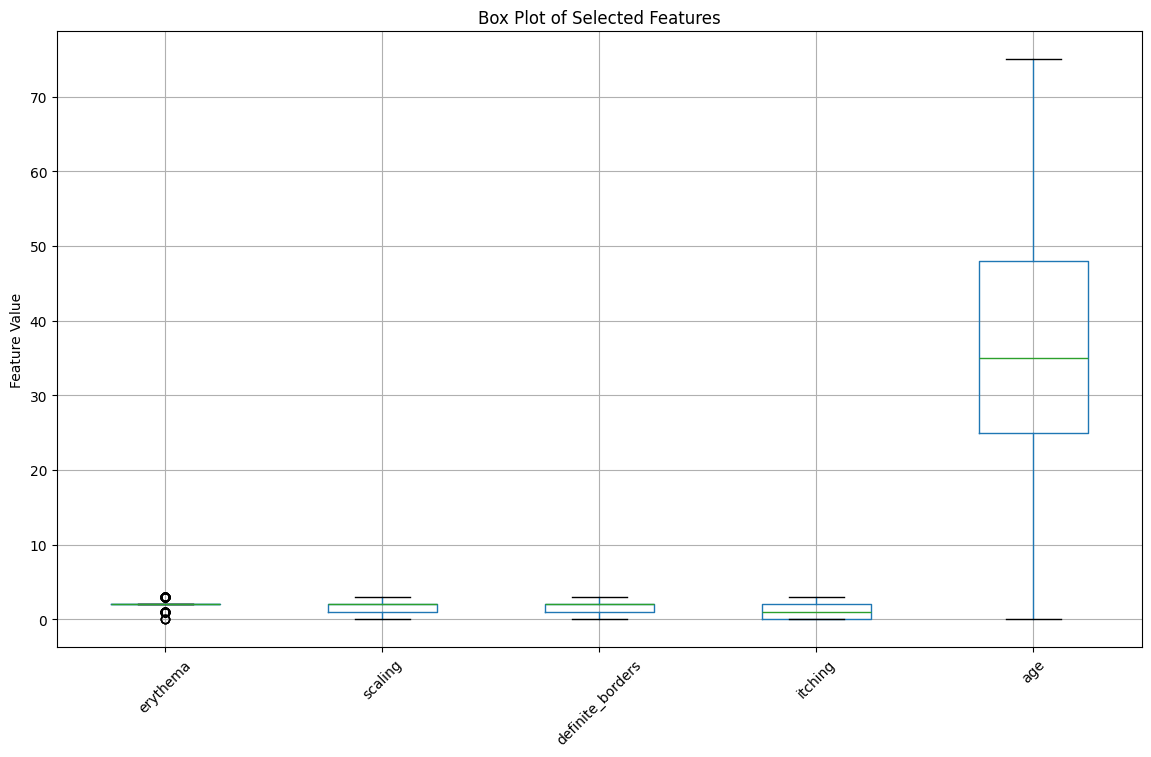

In [12]:
# Create boxplots for selected features

selected_features = [
    "erythema",
    "scaling",
    "definite_borders",
    "itching",
    "age"
]

plt.figure(figsize=(14, 8))

df[selected_features].boxplot()

plt.title("Box Plot of Selected Features")
plt.ylabel("Feature Value")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

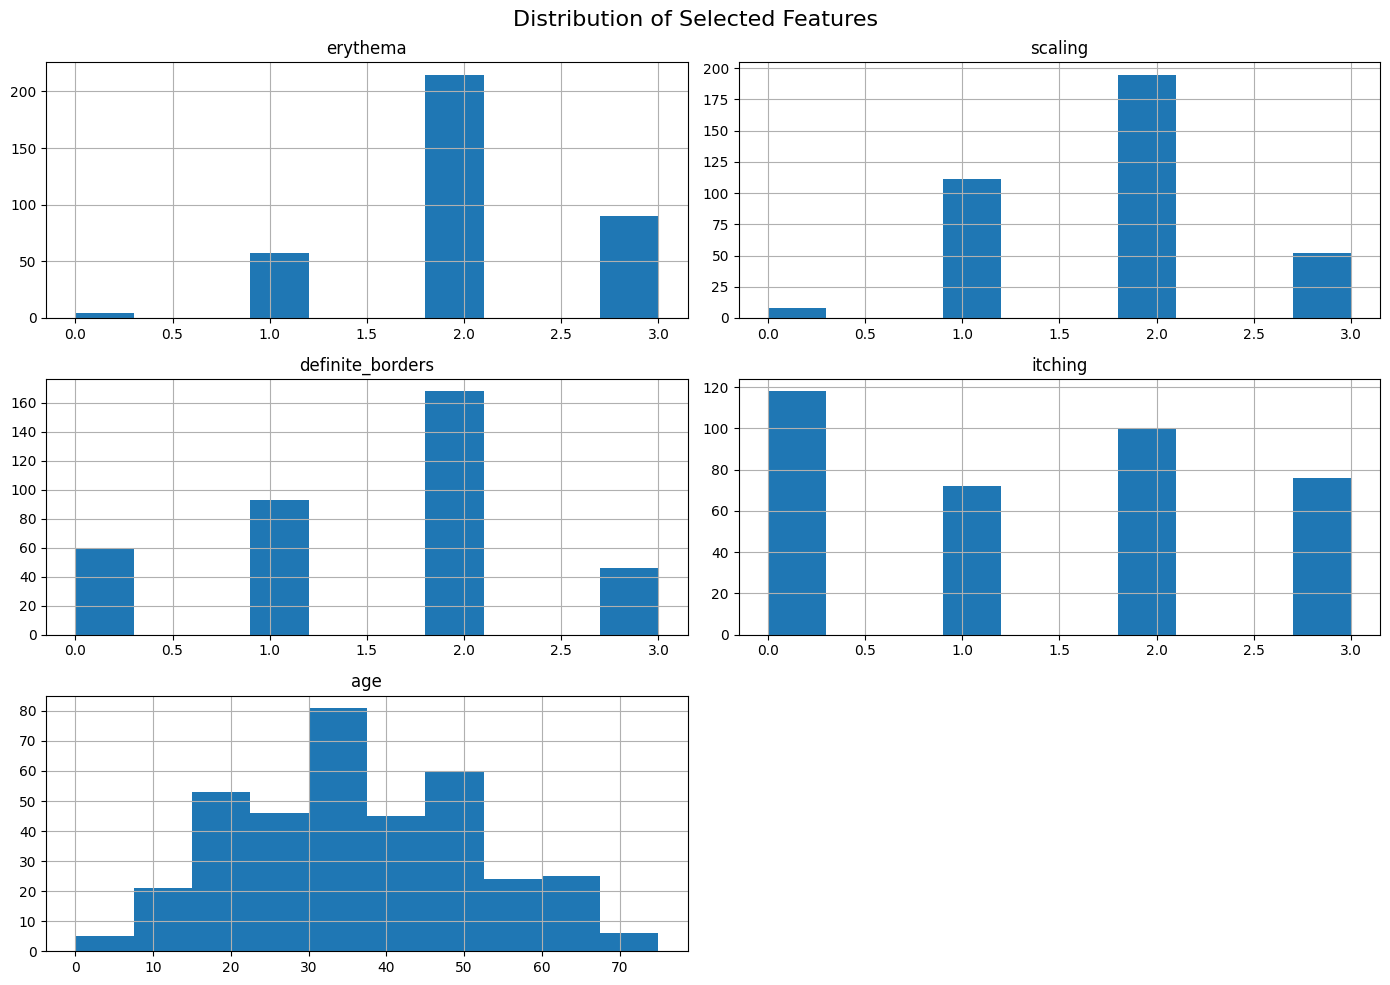

In [13]:
# Histograms for selected features

df[selected_features].hist(
    figsize=(14, 10),
    bins=10
)

plt.suptitle("Distribution of Selected Features", fontsize=16)
plt.tight_layout()
plt.show()

Class Distribution:
class
1    112
2     61
3     72
4     49
5     52
6     20
Name: count, dtype: int64


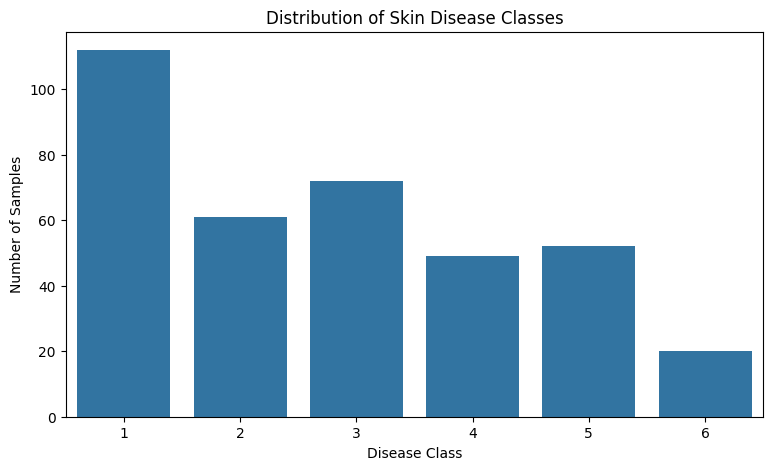

In [14]:
# Class distribution

class_counts = df["class"].value_counts().sort_index()

print("Class Distribution:")
print(class_counts)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Distribution of Skin Disease Classes")
plt.xlabel("Disease Class")
plt.ylabel("Number of Samples")

plt.show()

In [15]:
# Map class numbers to disease names

class_names = {
    1: "Psoriasis",
    2: "Seboreic Dermatitis",
    3: "Lichen Planus",
    4: "Pityriasis Rosea",
    5: "Cronic Dermatitis",
    6: "Pityriasis Rubra Pilaris"
}

class_distribution_named = class_counts.rename(index=class_names)

class_distribution_named

,count
class,
Psoriasis,112
Seboreic Dermatitis,61
Lichen Planus,72
Pityriasis Rosea,49
Cronic Dermatitis,52
Pityriasis Rubra Pilaris,20


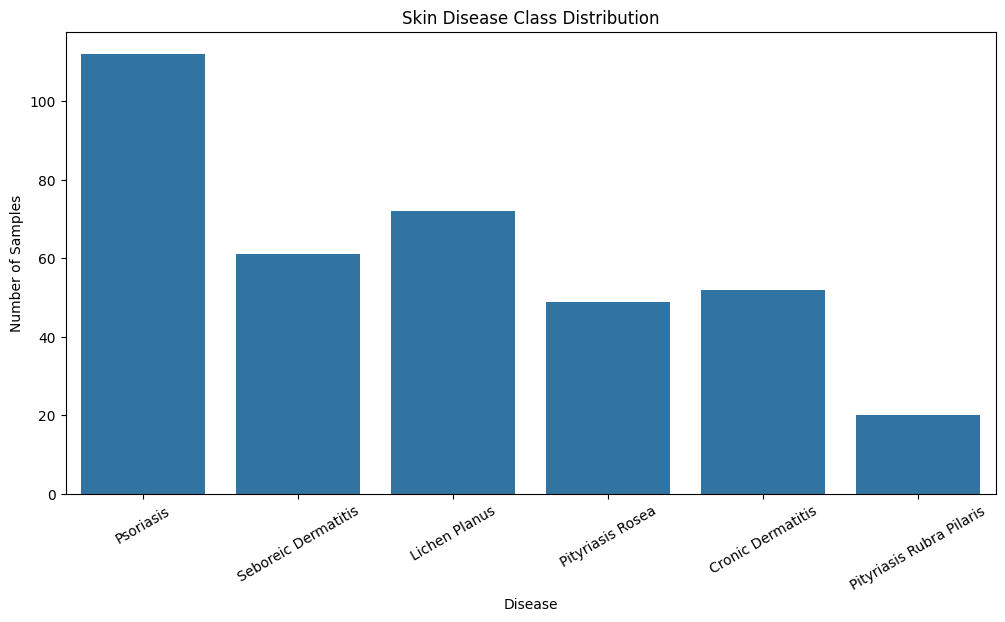

In [16]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=class_distribution_named.index,
    y=class_distribution_named.values
)

plt.title("Skin Disease Class Distribution")
plt.xlabel("Disease")
plt.ylabel("Number of Samples")

plt.xticks(rotation=30)
plt.show()

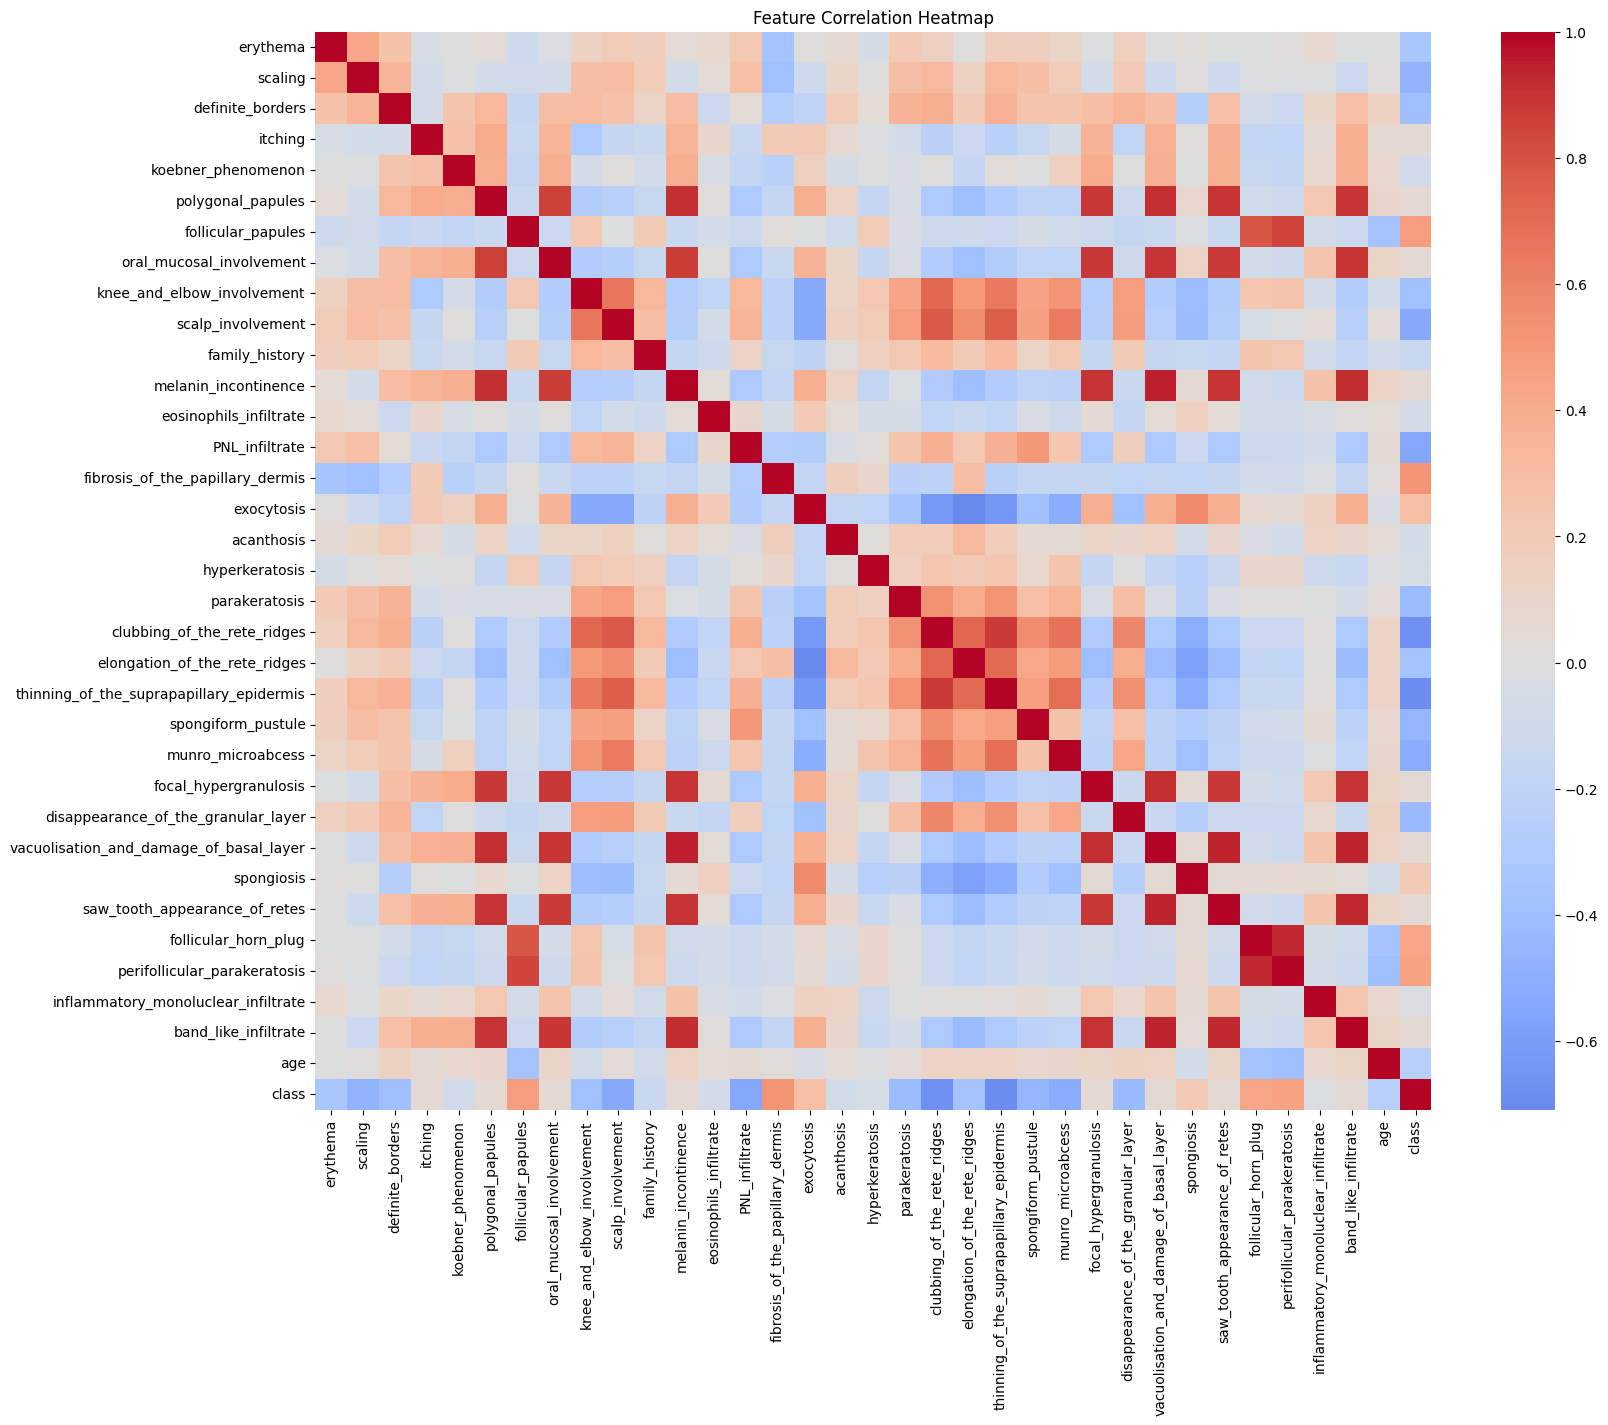

In [17]:
# Correlation matrix

correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [18]:
# Separate features and target

X = df.drop(columns=["class"])
y = df["class"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(sorted(y.unique()))

Feature shape: (366, 34)
Target shape: (366,)

Target classes:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [19]:
# Encode target variable

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Original classes:")
print(label_encoder.classes_)

print("\nEncoded classes:")
print(np.unique(y_encoded))

Original classes:
[1 2 3 4 5 6]

Encoded classes:
[0 1 2 3 4 5]


In [20]:
# Stratified 80/20 train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training samples: 292
Testing samples: 74

Training class distribution:
0    89
1    49
2    57
3    39
4    42
5    16
Name: count, dtype: int64

Testing class distribution:
0    23
1    12
2    15
3    10
4    10
5     4
Name: count, dtype: int64


In [21]:
# Standardize features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature standardization completed.")

print("\nMean of first 5 standardized features:")
print(X_train_scaled[:, :5].mean(axis=0))

print("\nStandard deviation of first 5 standardized features:")
print(X_train_scaled[:, :5].std(axis=0))

Feature standardization completed.

Mean of first 5 standardized features:
[ 1.97710950e-16  7.90843798e-17 -7.14801125e-17 -9.73346213e-17
 -2.73753623e-17]

Standard deviation of first 5 standardized features:
[1. 1. 1. 1. 1.]


In [22]:
# Define 5 multiclass classification models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("Models created:")
for name in models:
    print("-", name)

Models created:
- Logistic Regression
- KNN
- SVM
- Random Forest
- Gradient Boosting


In [23]:
# Train all models

trained_models = {}

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    trained_models[name] = model

    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
KNN trained successfully.
SVM trained successfully.
Random Forest trained successfully.
Gradient Boosting trained successfully.


In [24]:
# Generate predictions from all models

predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test_scaled)

    predictions[name] = y_pred

print("Predictions generated for all models.")

Predictions generated for all models.


In [25]:
# Calculate evaluation metrics

results = []

for name, y_pred in predictions.items():

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

results_df.sort_values(
    by="Accuracy",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
2,SVM,0.972973,0.977477,0.972973,0.972973
0,Logistic Regression,0.959459,0.968815,0.959459,0.960642
3,Random Forest,0.959459,0.960688,0.959459,0.959543
4,Gradient Boosting,0.932432,0.933277,0.932432,0.930944
1,KNN,0.905405,0.919305,0.905405,0.908094


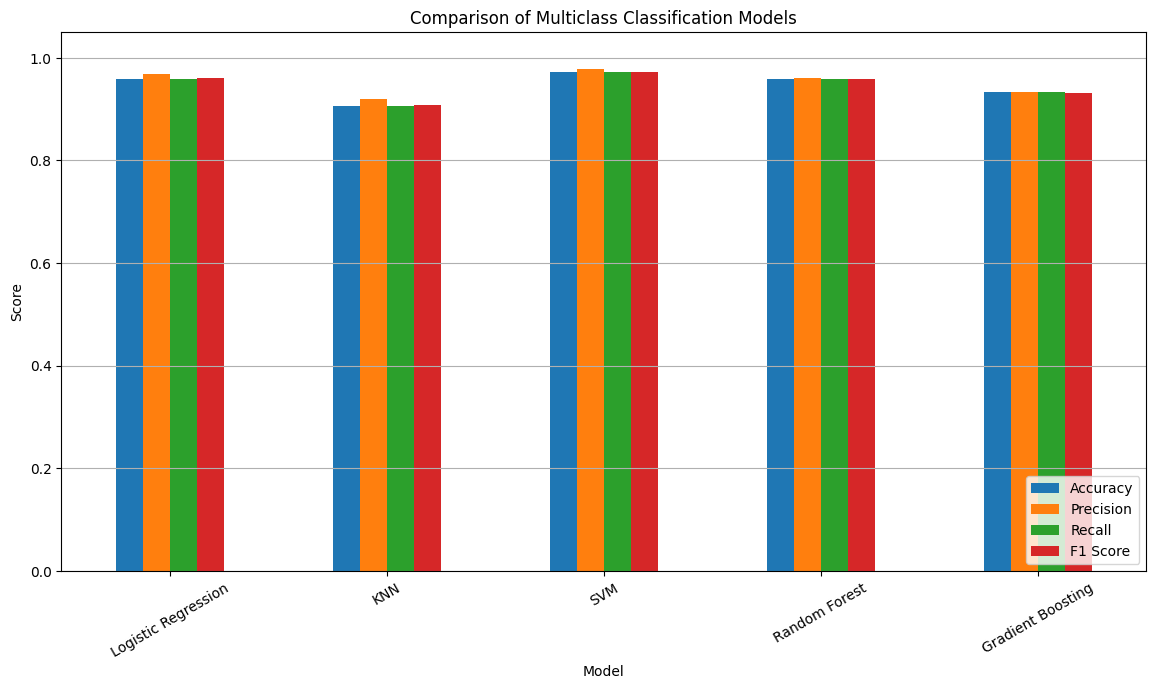

In [26]:
# Plot model performance

results_plot = results_df.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Comparison of Multiclass Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)

plt.xticks(rotation=30)
plt.grid(axis="y")

plt.legend(loc="lower right")

plt.show()

In [27]:
# Detailed classification report for every model

target_names = [
    class_names[i]
    for i in sorted(class_names.keys())
]

for name, y_pred in predictions.items():

    print("=" * 80)
    print(name)
    print("=" * 80)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=target_names,
            digits=4,
            zero_division=0
        )
    )

Logistic Regression
                          precision    recall  f1-score   support

               Psoriasis     1.0000    1.0000    1.0000        23
     Seboreic Dermatitis     1.0000    0.8333    0.9091        12
           Lichen Planus     1.0000    0.9333    0.9655        15
        Pityriasis Rosea     0.7692    1.0000    0.8696        10
       Cronic Dermatitis     1.0000    1.0000    1.0000        10
Pityriasis Rubra Pilaris     1.0000    1.0000    1.0000         4

                accuracy                         0.9595        74
               macro avg     0.9615    0.9611    0.9574        74
            weighted avg     0.9688    0.9595    0.9606        74

KNN
                          precision    recall  f1-score   support

               Psoriasis     1.0000    0.9565    0.9778        23
     Seboreic Dermatitis     0.8000    0.6667    0.7273        12
           Lichen Planus     1.0000    0.9333    0.9655        15
        Pityriasis Rosea     0.6429    0.9000   

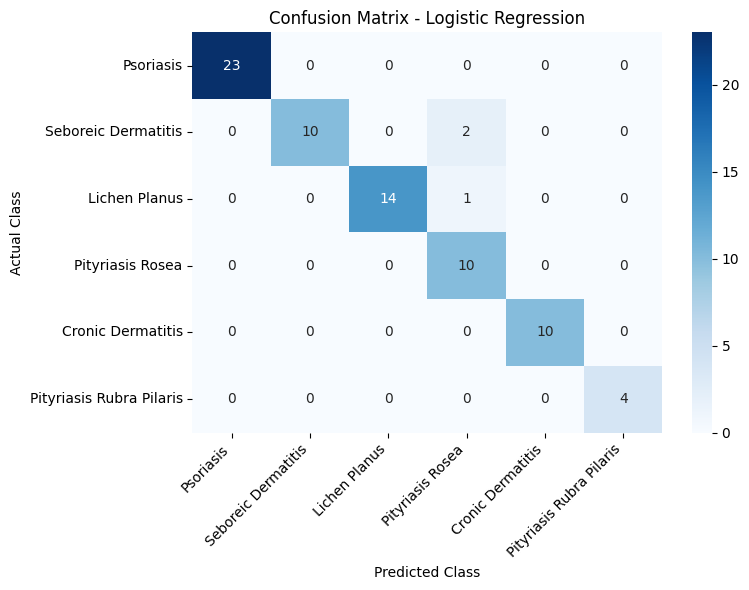

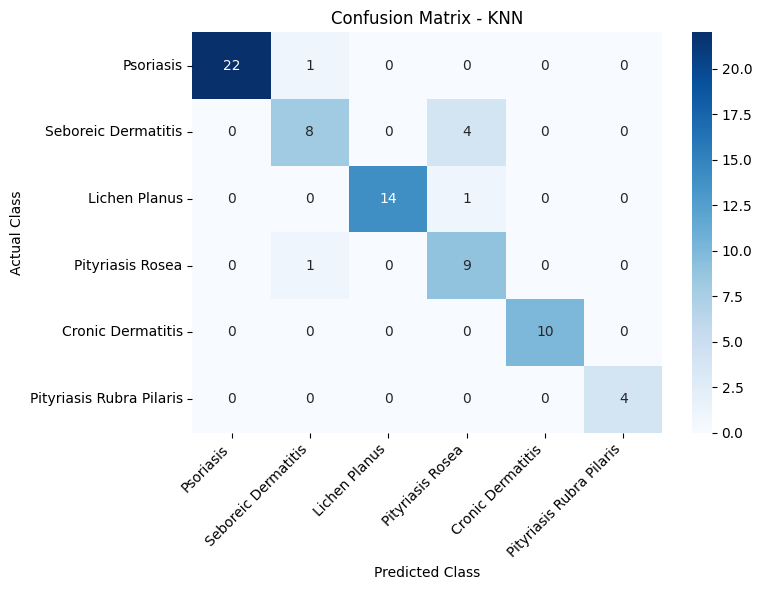

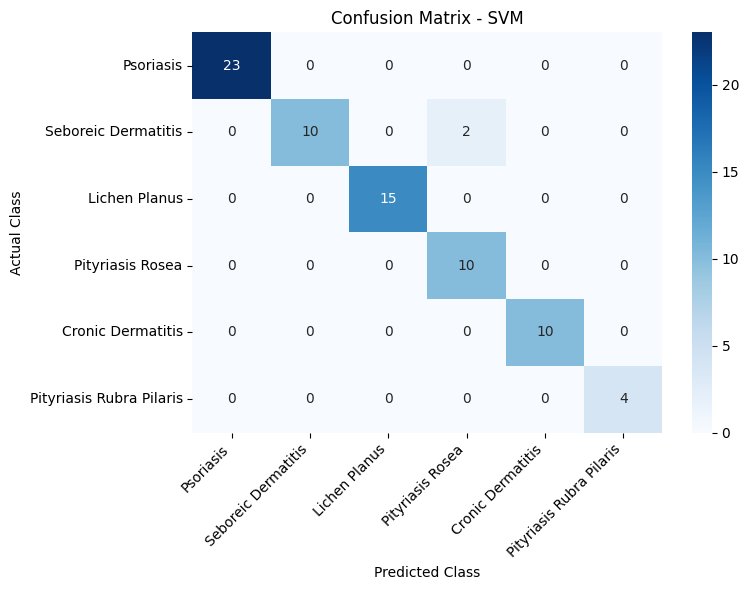

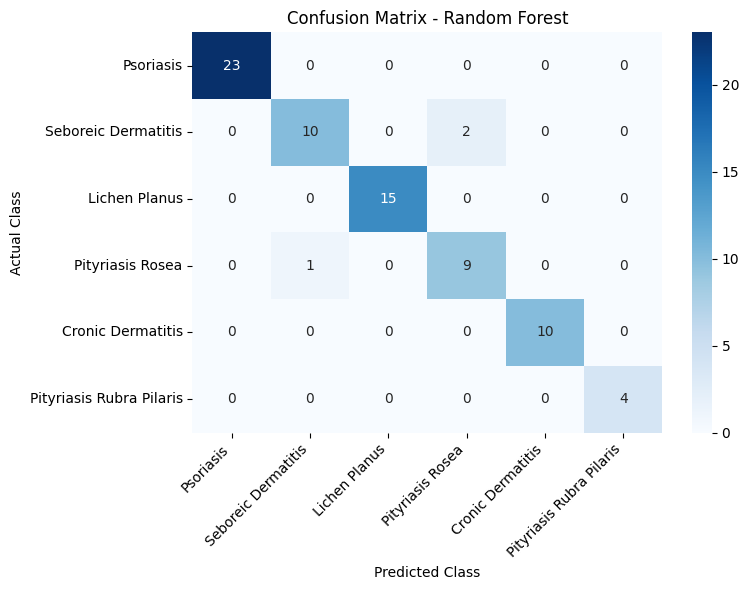

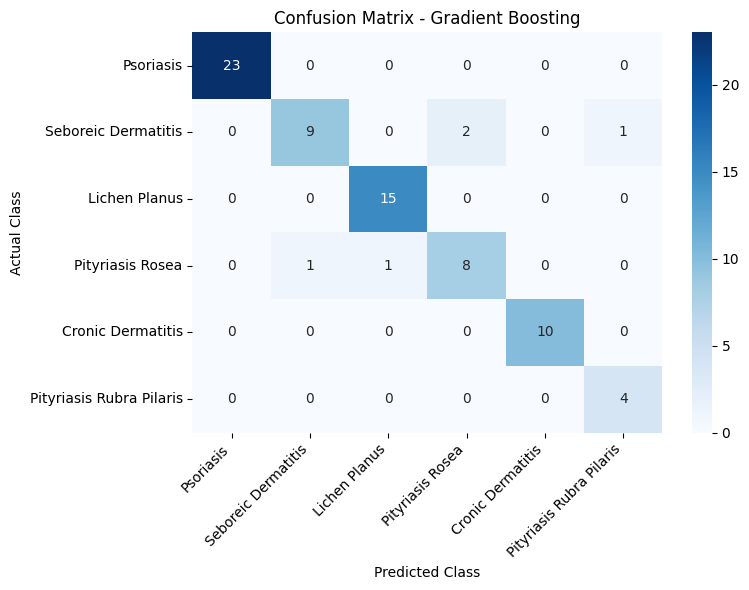

In [28]:
# Confusion matrices

for name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=target_names,
        yticklabels=target_names
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

In [29]:
# Convert test labels to one-vs-rest format

n_classes = len(np.unique(y_encoded))

y_test_binary = label_binarize(
    y_test,
    classes=np.arange(n_classes)
)

print("Number of classes:", n_classes)
print("Binary target shape:", y_test_binary.shape)

Number of classes: 6
Binary target shape: (74, 6)


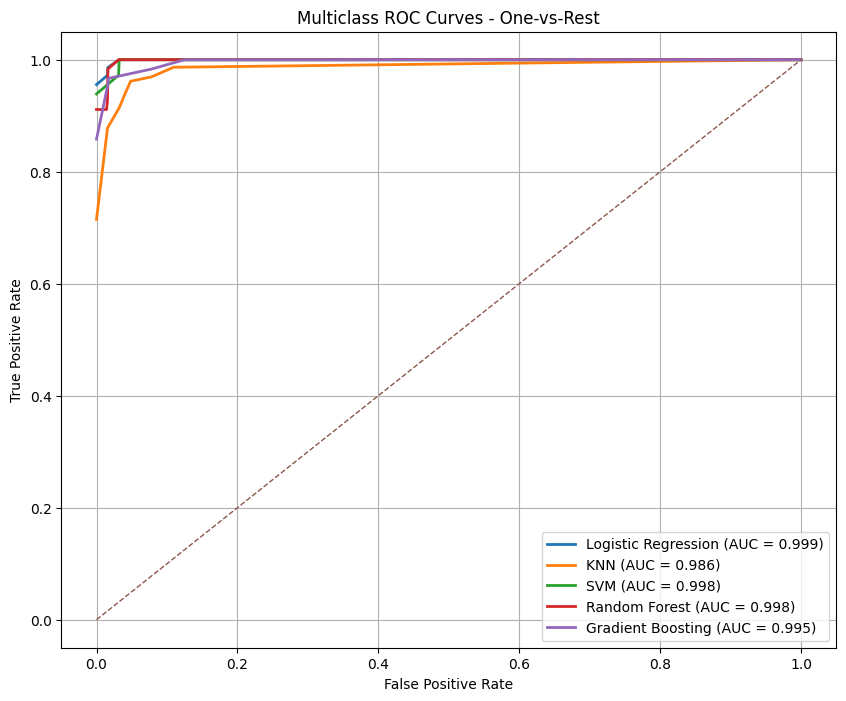

In [30]:
# Plot macro-average ROC curve for all models

plt.figure(figsize=(10, 8))

auc_scores = {}

for name, model in trained_models.items():

    # Get probability predictions
    y_score = model.predict_proba(X_test_scaled)

    # Calculate macro AUC
    macro_auc = roc_auc_score(
        y_test_binary,
        y_score,
        multi_class="ovr",
        average="macro"
    )

    auc_scores[name] = macro_auc

    # Calculate ROC curve for each class
    fpr = {}
    tpr = {}

    for i in range(n_classes):

        fpr[i], tpr[i], _ = roc_curve(
            y_test_binary[:, i],
            y_score[:, i]
        )

    # Create macro-average ROC curve

    all_fpr = np.unique(
        np.concatenate(
            [fpr[i] for i in range(n_classes)]
        )
    )

    mean_tpr = np.zeros_like(all_fpr)

    for i in range(n_classes):
        mean_tpr += np.interp(
            all_fpr,
            fpr[i],
            tpr[i]
        )

    mean_tpr /= n_classes

    plt.plot(
        all_fpr,
        mean_tpr,
        linewidth=2,
        label=f"{name} (AUC = {macro_auc:.3f})"
    )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Multiclass ROC Curves - One-vs-Rest")

plt.legend(loc="lower right")

plt.grid(True)

plt.show()

In [31]:
# Display AUC scores

auc_df = pd.DataFrame(
    auc_scores.items(),
    columns=["Model", "Macro AUC"]
)

auc_df = auc_df.sort_values(
    by="Macro AUC",
    ascending=False
)

auc_df

,Model,Macro AUC
0,Logistic Regression,0.999068
3,Random Forest,0.998323
2,SVM,0.998062
4,Gradient Boosting,0.994858
1,KNN,0.986262


Best model according to Macro AUC:
Logistic Regression


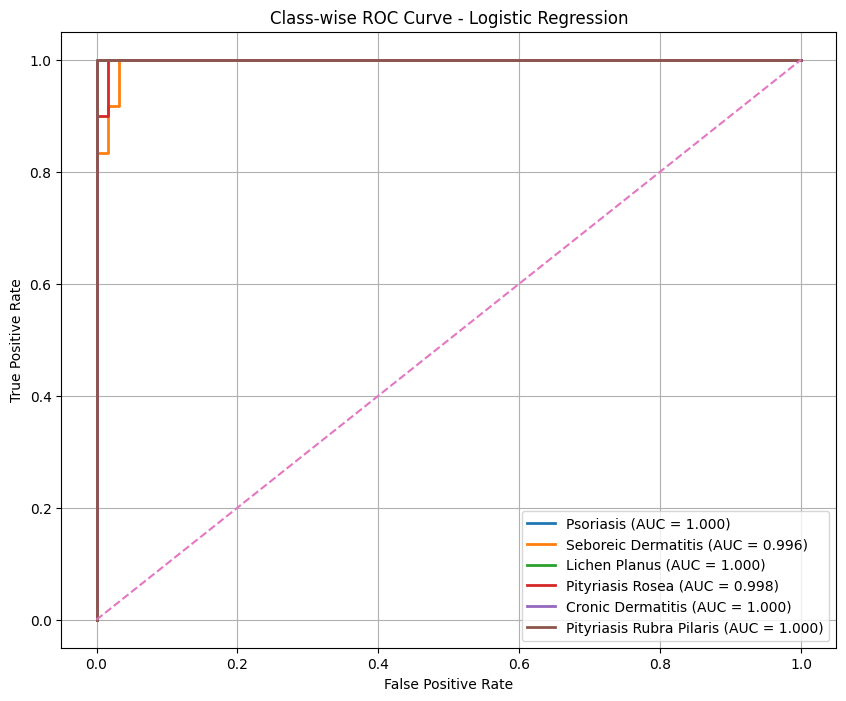

In [32]:
# Select best model according to Macro AUC

best_model_name = auc_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best model according to Macro AUC:")
print(best_model_name)

# Probability predictions
y_score = best_model.predict_proba(X_test_scaled)

plt.figure(figsize=(10, 8))

for i in range(n_classes):

    fpr, tpr, _ = roc_curve(
        y_test_binary[:, i],
        y_score[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{target_names[i]} (AUC = {class_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"Class-wise ROC Curve - {best_model_name}"
)

plt.legend(loc="lower right")

plt.grid(True)

plt.show()

In [33]:
# Combine all important metrics into one table

final_results = results_df.merge(
    auc_df,
    on="Model"
)

final_results = final_results.sort_values(
    by="Accuracy",
    ascending=False
)

final_results.reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1 Score,Macro AUC
0,SVM,0.972973,0.977477,0.972973,0.972973,0.998062
1,Logistic Regression,0.959459,0.968815,0.959459,0.960642,0.999068
2,Random Forest,0.959459,0.960688,0.959459,0.959543,0.998323
3,Gradient Boosting,0.932432,0.933277,0.932432,0.930944,0.994858
4,KNN,0.905405,0.919305,0.905405,0.908094,0.986262


In [34]:
# Identify the best model

best_accuracy_model = final_results.iloc[0]

print("BEST MODEL BASED ON ACCURACY")
print("-" * 40)

print("Model:", best_accuracy_model["Model"])
print("Accuracy:", round(best_accuracy_model["Accuracy"], 4))
print("Precision:", round(best_accuracy_model["Precision"], 4))
print("Recall:", round(best_accuracy_model["Recall"], 4))
print("F1 Score:", round(best_accuracy_model["F1 Score"], 4))
print("Macro AUC:", round(best_accuracy_model["Macro AUC"], 4))

BEST MODEL BASED ON ACCURACY
----------------------------------------
Model: SVM
Accuracy: 0.973
Precision: 0.9775
Recall: 0.973
F1 Score: 0.973
Macro AUC: 0.9981


In [35]:
# Detailed report for the best accuracy model

best_name = best_accuracy_model["Model"]

print(f"Classification Report - {best_name}")
print("=" * 70)

print(
    classification_report(
        y_test,
        predictions[best_name],
        target_names=target_names,
        digits=4,
        zero_division=0
    )
)

Classification Report - SVM
                          precision    recall  f1-score   support

               Psoriasis     1.0000    1.0000    1.0000        23
     Seboreic Dermatitis     1.0000    0.8333    0.9091        12
           Lichen Planus     1.0000    1.0000    1.0000        15
        Pityriasis Rosea     0.8333    1.0000    0.9091        10
       Cronic Dermatitis     1.0000    1.0000    1.0000        10
Pityriasis Rubra Pilaris     1.0000    1.0000    1.0000         4

                accuracy                         0.9730        74
               macro avg     0.9722    0.9722    0.9697        74
            weighted avg     0.9775    0.9730    0.9730        74



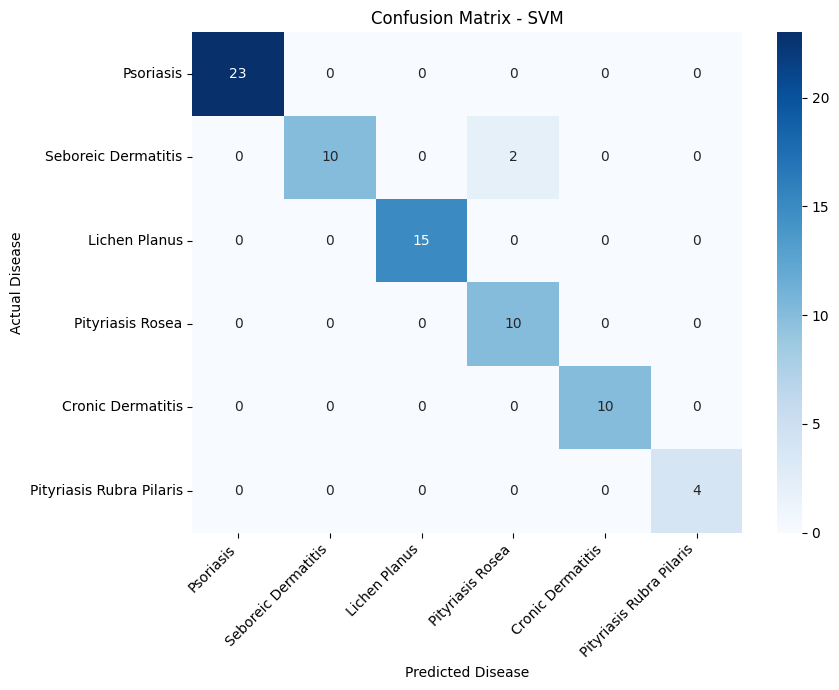

In [36]:
# Confusion matrix of best model

best_predictions = predictions[best_name]

cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names
)

plt.title(f"Confusion Matrix - {best_name}")

plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

In [37]:
# Feature importance from Random Forest

rf_model = trained_models["Random Forest"]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
19,clubbing_of_the_rete_ridges,0.103995
14,fibrosis_of_the_papillary_dermis,0.078025
21,thinning_of_the_suprapapillary_epidermis,0.070083
4,koebner_phenomenon,0.061630
27,spongiosis,0.055657
20,elongation_of_the_rete_ridges,0.054517
13,PNL_infiltrate,0.041216
26,vacuolisation_and_damage_of_basal_layer,0.039338
28,saw_tooth_appearance_of_retes,0.038373
32,band_like_infiltrate,0.034791


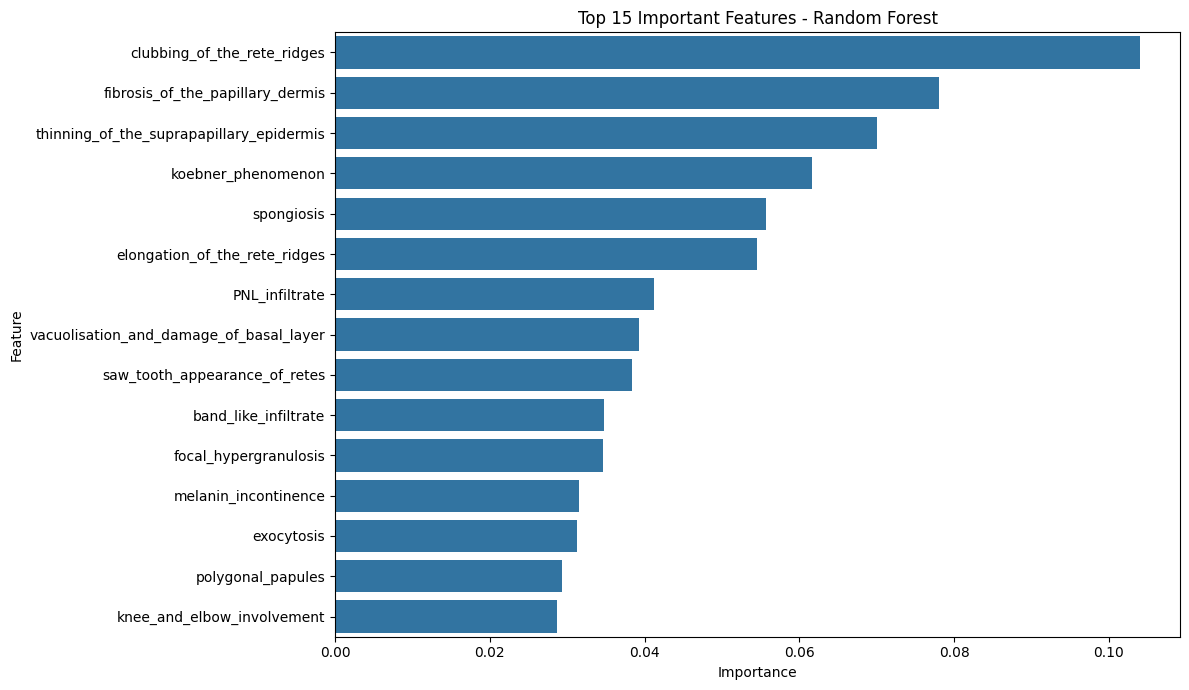

In [38]:
# Plot top 15 important features

top_features = feature_importance.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.show()

In [39]:
# Calculate class proportions

class_proportions = (
    df["class"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

imbalance_df = pd.DataFrame({
    "Class": class_proportions.index,
    "Disease": [
        class_names[i]
        for i in class_proportions.index
    ],
    "Percentage": class_proportions.values
})

imbalance_df

,Class,Disease,Percentage
0,1,Psoriasis,30.601093
1,2,Seboreic Dermatitis,16.666667
2,3,Lichen Planus,19.672131
3,4,Pityriasis Rosea,13.387978
4,5,Cronic Dermatitis,14.207650
5,6,Pityriasis Rubra Pilaris,5.464481


In [40]:
# Generate a simple interpretation based on model results

best_model = final_results.iloc[0]

print("INTERPRETATION")
print("=" * 70)

print(
    f"The best performing model based on accuracy was "
    f"{best_model['Model']} with an accuracy of "
    f"{best_model['Accuracy']:.2%}."
)

print(
    f"Its weighted precision was {best_model['Precision']:.2%}, "
    f"weighted recall was {best_model['Recall']:.2%}, "
    f"and weighted F1-score was {best_model['F1 Score']:.2%}."
)

print(
    f"The macro-average ROC-AUC score was "
    f"{best_model['Macro AUC']:.3f}."
)

print("\nThe confusion matrix can be used to identify which")
print("skin disease classes are most frequently confused.")

print("\nSince this is a multiclass problem, performance should")
print("not be judged using accuracy alone. Per-class precision,")
print("recall and F1-score should also be considered.")

INTERPRETATION
The best performing model based on accuracy was SVM with an accuracy of 97.30%.
Its weighted precision was 97.75%, weighted recall was 97.30%, and weighted F1-score was 97.30%.
The macro-average ROC-AUC score was 0.998.

The confusion matrix can be used to identify which
skin disease classes are most frequently confused.

Since this is a multiclass problem, performance should
not be judged using accuracy alone. Per-class precision,
recall and F1-score should also be considered.
